# King County House Price Prediction

Goal: predict house sale price with a clear, leakage-safe regression workflow.

## 1. Import libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
DATA_PATH = 'kc_house_data_NaN.csv'

print('Libraries imported.')

Libraries imported.


## 1. Load the dataset

In [2]:
data = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {data.shape}')
display(data.head())

Dataset shape: (21613, 22)


,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 1. Inspect dataset structure and data types

In [3]:
data.info()

print('\nData types:')
display(data.dtypes.to_frame('dtype'))

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  str    
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat            21

,dtype
Unnamed: 0,int64
id,int64
date,str
price,float64
bedrooms,float64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64


## 1. Review descriptive statistics and duplicates

In [4]:
display(data.describe(include='all').T)
print(f'Exact duplicate rows: {data.duplicated().sum():,}')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,21613.0,NaN,NaN,NaN,10806.0,6239.28002,0.0,5403.0,10806.0,16209.0,21612.0
id,21613.0,NaN,NaN,NaN,4580301520.864988,2876565571.312057,1000102.0,2123049194.0,3904930410.0,7308900445.0,9900000190.0
date,21613,372,20140623T000000,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,21613.0,NaN,NaN,NaN,540088.141767,367127.196483,75000.0,321950.0,450000.0,645000.0,7700000.0
bedrooms,21600.0,NaN,NaN,NaN,3.37287,0.926657,1.0,3.0,3.0,4.0,33.0
bathrooms,21603.0,NaN,NaN,NaN,2.115736,0.768996,0.5,1.75,2.25,2.5,8.0
sqft_living,21613.0,NaN,NaN,NaN,2079.899736,918.440897,290.0,1427.0,1910.0,2550.0,13540.0
sqft_lot,21613.0,NaN,NaN,NaN,15106.967566,41420.511515,520.0,5040.0,7618.0,10688.0,1651359.0
floors,21613.0,NaN,NaN,NaN,1.494309,0.539989,1.0,1.0,1.5,2.0,3.5
waterfront,21613.0,NaN,NaN,NaN,0.007542,0.086517,0.0,0.0,0.0,0.0,1.0


Exact duplicate rows: 0


## 2. Check missing values

In [5]:
missing_summary = pd.DataFrame({
    'missing_count': data.isna().sum(),
    'missing_percent': (data.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)

display(missing_summary[missing_summary['missing_count'] > 0])

,missing_count,missing_percent
bedrooms,13,0.06
bathrooms,10,0.05


## 2. Count unique values and measure skewness

In [6]:
unique_summary = data.nunique().sort_values().to_frame('unique_values')
skewness_summary = data.select_dtypes(include=np.number).skew().sort_values(ascending=False).to_frame('skewness')

print('Unique values:')
display(unique_summary)
print('Numeric skewness:')
display(skewness_summary)

Unique values:

,unique_values
waterfront,2
view,5
condition,5
floors,6
bedrooms,12
grade,12
bathrooms,29
yr_renovated,70
zipcode,70
yr_built,116


Numeric skewness:


,skewness
sqft_lot,13.060019
waterfront,11.385108
sqft_lot15,9.506743
yr_renovated,4.549493
price,4.024069
view,3.395750
bedrooms,2.019751
sqft_basement,1.577965
sqft_living,1.471555
sqft_above,1.446664


## 2. Detect IQR outliers in key numeric columns

,feature,q1,q3,lower_limit,upper_limit,outlier_count
0,price,321950.00,645000.0,-162625.000,1129575.000,1146
1,sqft_living,1427.00,2550.0,-257.500,4234.500,572
2,sqft_lot,5040.00,10688.0,-3432.000,19160.000,2425
3,bedrooms,3.00,4.0,1.500,5.500,533
4,bathrooms,1.75,2.5,0.625,3.625,561


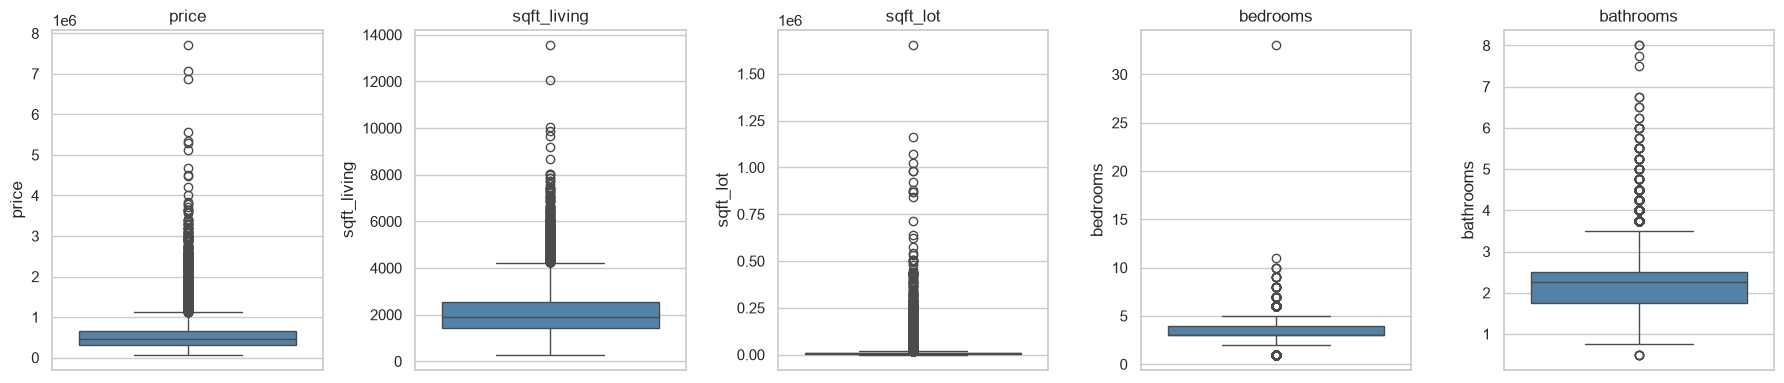

In [7]:
key_numeric_columns = ['price', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms']
outlier_rows = []

for column in key_numeric_columns:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_count = ((data[column] < lower_limit) | (data[column] > upper_limit)).sum()
    outlier_rows.append([column, q1, q3, lower_limit, upper_limit, outlier_count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=['feature', 'q1', 'q3', 'lower_limit', 'upper_limit', 'outlier_count']
)
display(outlier_summary)

fig, axes = plt.subplots(1, len(key_numeric_columns), figsize=(18, 4))
for axis, column in zip(axes, key_numeric_columns):
    sns.boxplot(y=data[column], color='steelblue', ax=axis)
    axis.set_title(column)
plt.tight_layout()
plt.show()

**Insight.** IQR flags unusually large homes, lots, and prices. These are plausible market observations, so the pipeline retains them and reduces their influence with robust scaling and a log target.

## 2. Visualize the price distribution before and after log transformation

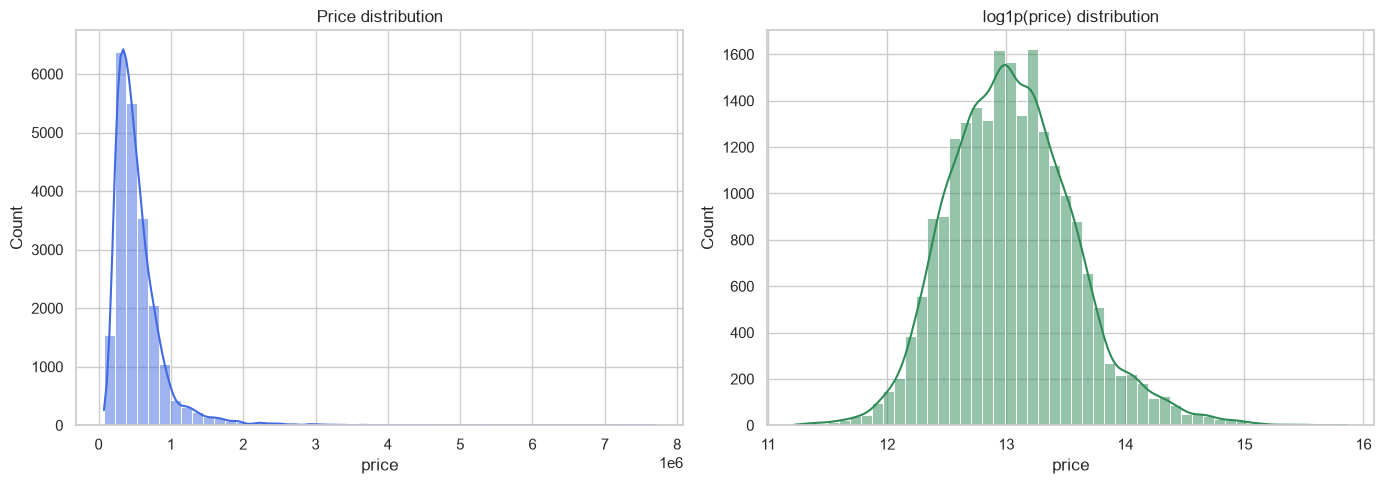

Raw price skewness: 4.02
Log price skewness: 0.43


In [8]:
log_price = np.log1p(data['price'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data['price'], bins=50, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title('Price distribution')
sns.histplot(log_price, bins=50, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title('log1p(price) distribution')
plt.tight_layout()
plt.show()

print(f'Raw price skewness: {data["price"].skew():.2f}')
print(f'Log price skewness: {log_price.skew():.2f}')

**Insight.** The log transformation reduces the long high-price tail. Models use log price, then return predictions to the original price scale for evaluation.

## 2. Plot the price boxplot

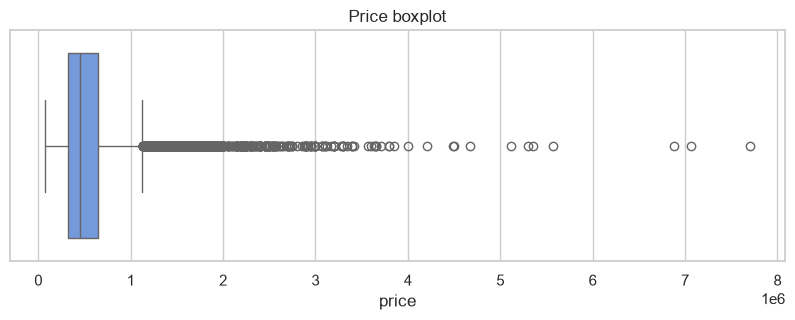

In [9]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=data['price'], color='cornflowerblue')
plt.title('Price boxplot')
plt.show()

**Insight.** The long upper tail represents valid luxury sales. Removing them would make the model less useful for the complete market.

## 2. Plot living-area features against price

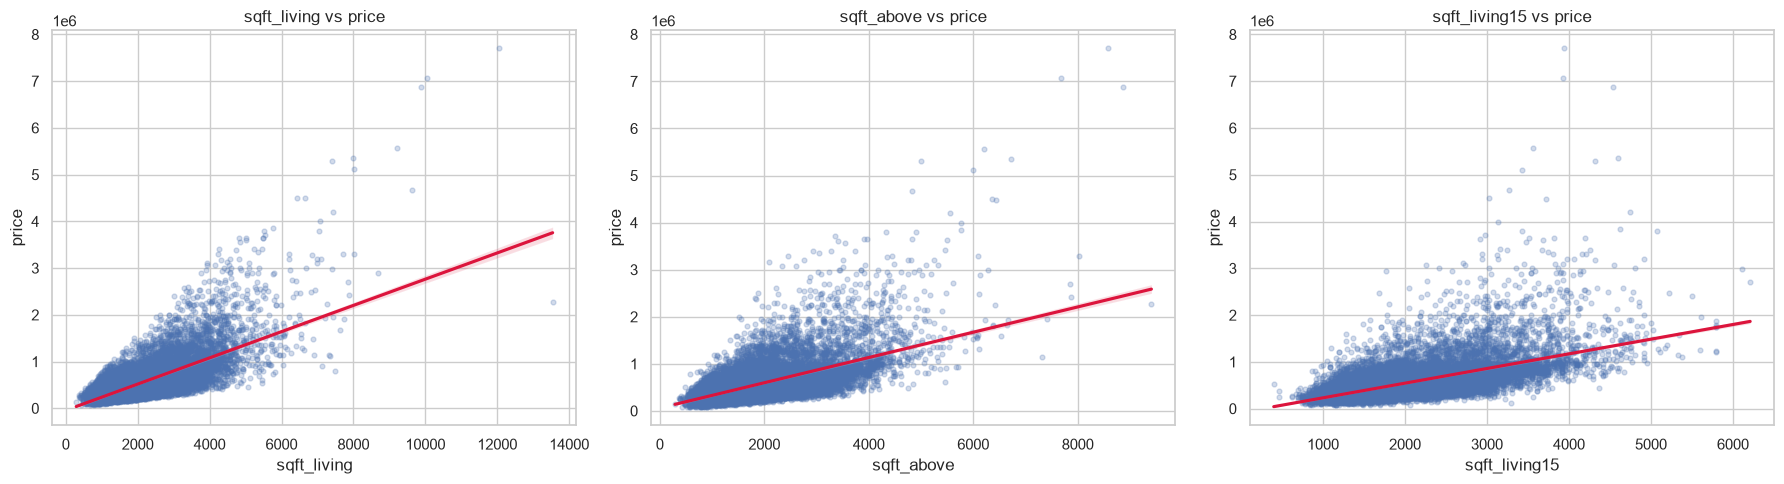

price            1.000000
sqft_living      0.702035
sqft_above       0.605567
sqft_living15    0.585379
Name: price, dtype: float64


In [10]:
area_features = ['sqft_living', 'sqft_above', 'sqft_living15']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, feature in zip(axes, area_features):
    sns.regplot(
        data=data,
        x=feature,
        y='price',
        scatter_kws={'alpha': 0.25, 's': 12},
        line_kws={'color': 'crimson'},
        ax=axis
    )
    axis.set_title(f'{feature} vs price')
plt.tight_layout()
plt.show()

print(data[area_features + ['price']].corr()['price'].sort_values(ascending=False))

**Insight.** Living area should show a strong positive relationship with price. Total living area is used as the primary size feature.

## 2. Compare category features with price

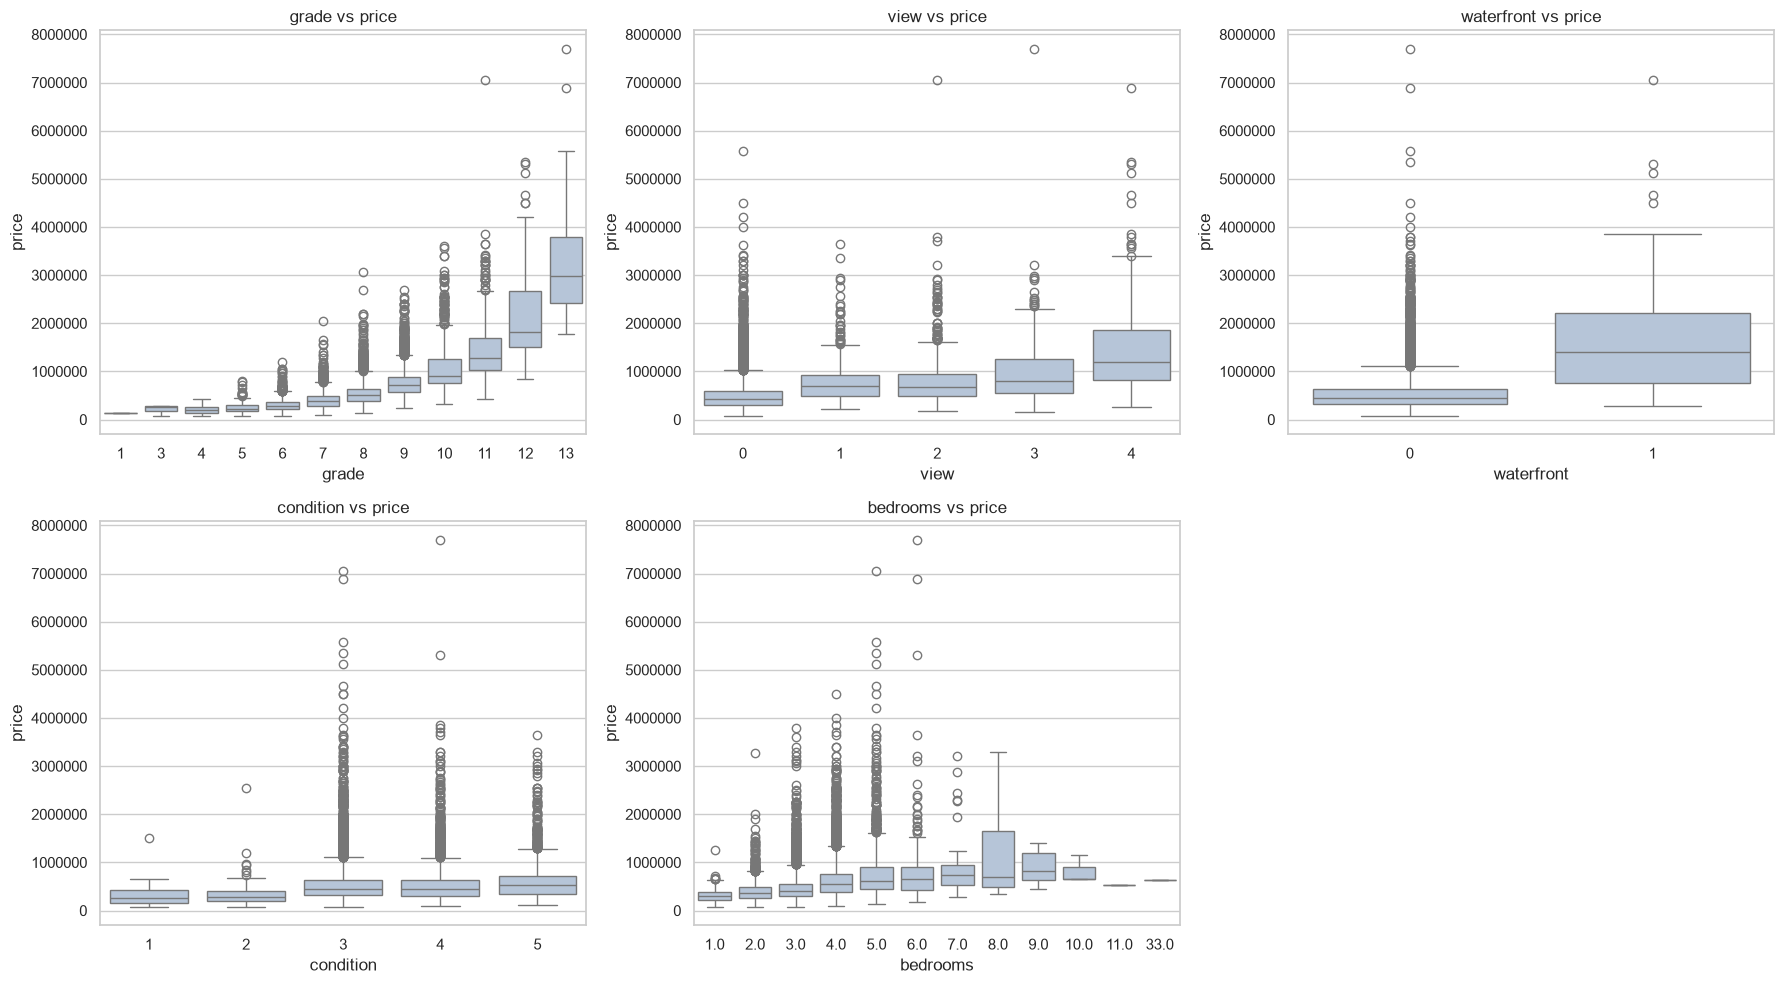

,count,mean,median
waterfront,,,
0,21450,531564.0,450000.0
1,163,1661876.0,1400000.0


In [11]:
category_features = ['grade', 'view', 'waterfront', 'condition', 'bedrooms']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for axis, feature in zip(axes.flat, category_features):
    sns.boxplot(data=data, x=feature, y='price', color='lightsteelblue', ax=axis)
    axis.set_title(f'{feature} vs price')
    axis.ticklabel_format(style='plain', axis='y')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

display(data.groupby('waterfront')['price'].agg(['count', 'mean', 'median']).round(0))

**Insight.** Grade, view, and waterfront status can separate price levels. Bedrooms are useful, but total area and quality provide more complete information.

## 2. Plot the correlation heatmap

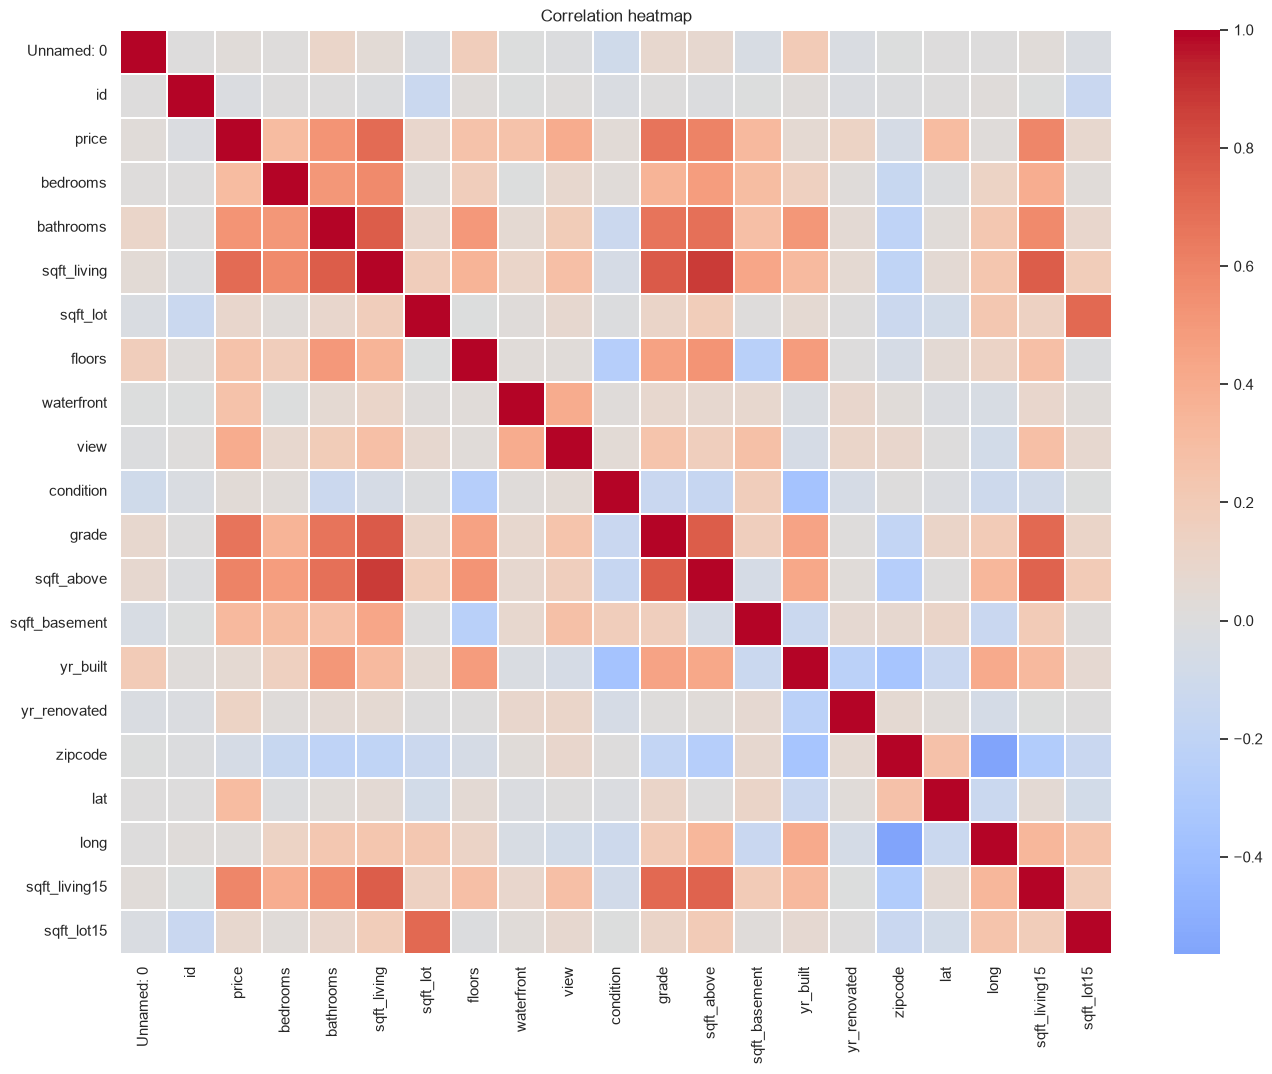

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525885
view             0.397293
sqft_basement    0.323816
bedrooms         0.308890
lat              0.307003
Name: price, dtype: float64


In [12]:
correlation_matrix = data.select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, cmap='coolwarm', center=0, linewidths=0.25)
plt.title('Correlation heatmap')
plt.show()

print(correlation_matrix['price'].sort_values(ascending=False).head(10))

**Insight.** The heatmap identifies useful price relationships and redundant size variables. It supports the later correlation and VIF feature-selection step.

## 2. Plot numeric feature histograms

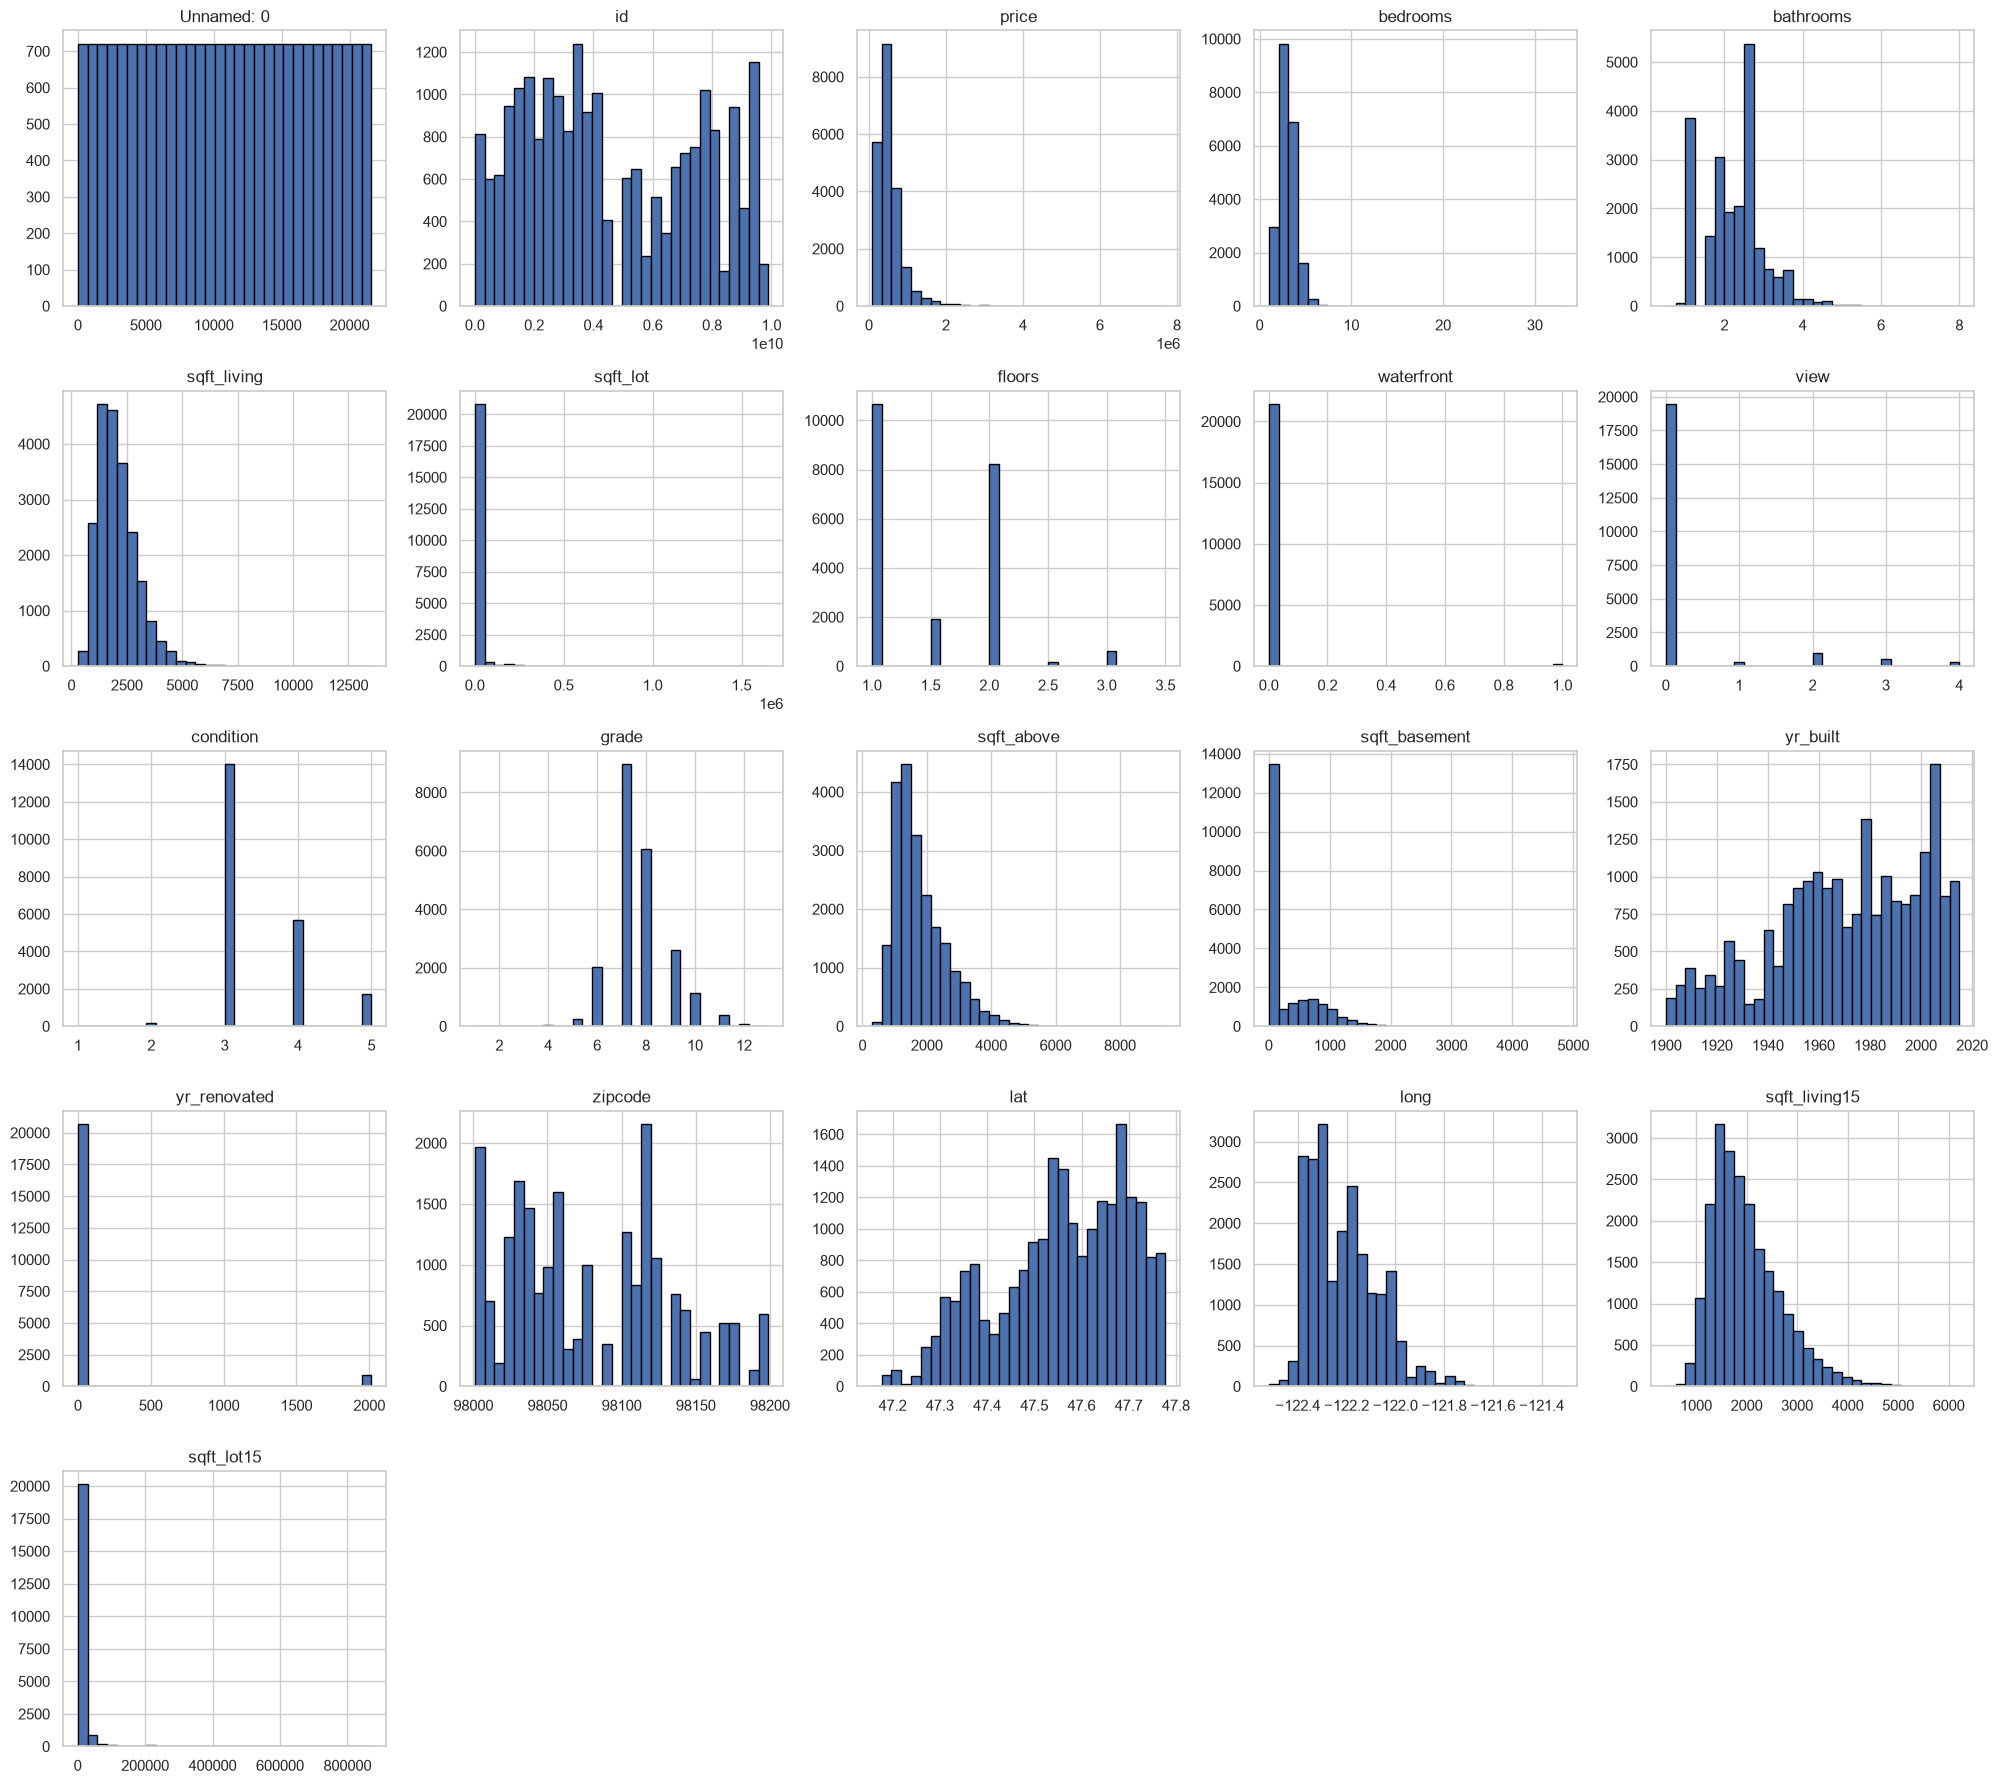

In [13]:
data.select_dtypes(include=np.number).hist(figsize=(20, 18), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

**Insight.** Several size variables are right-skewed. RobustScaler uses medians and interquartile ranges, so it is less affected by extreme values.

## 2. Map home prices by latitude and longitude

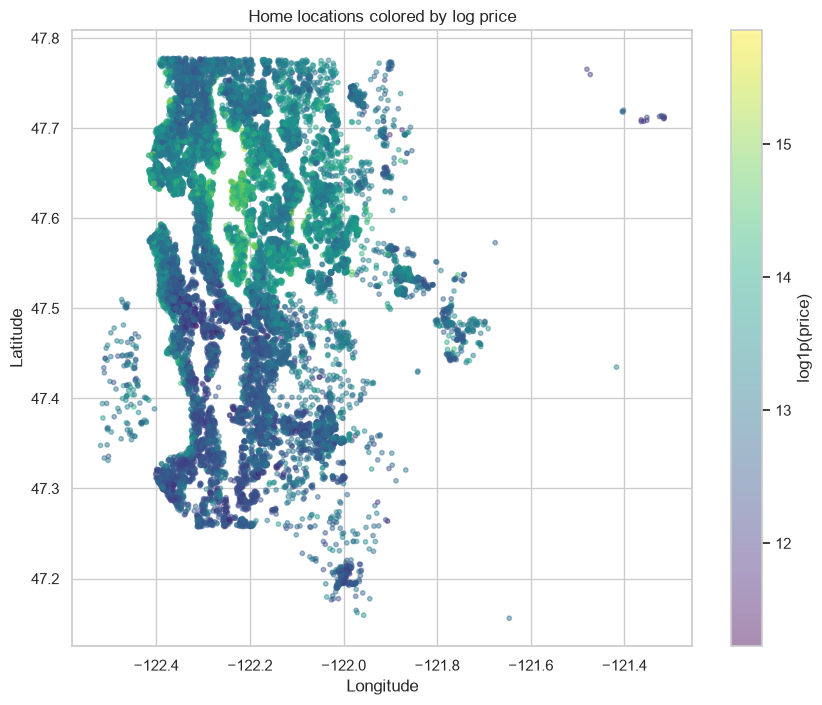

In [14]:
plt.figure(figsize=(10, 8))
points = plt.scatter(
    data['long'],
    data['lat'],
    c=np.log1p(data['price']),
    cmap='viridis',
    alpha=0.45,
    s=10
)
plt.colorbar(points, label='log1p(price)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Home locations colored by log price')
plt.show()

**Insight.** Price clusters geographically, which supports using location as a model input. Zip code is encoded categorically rather than treated as an ordered number.

## 2. Compare average price by zip code, year built, and sale month

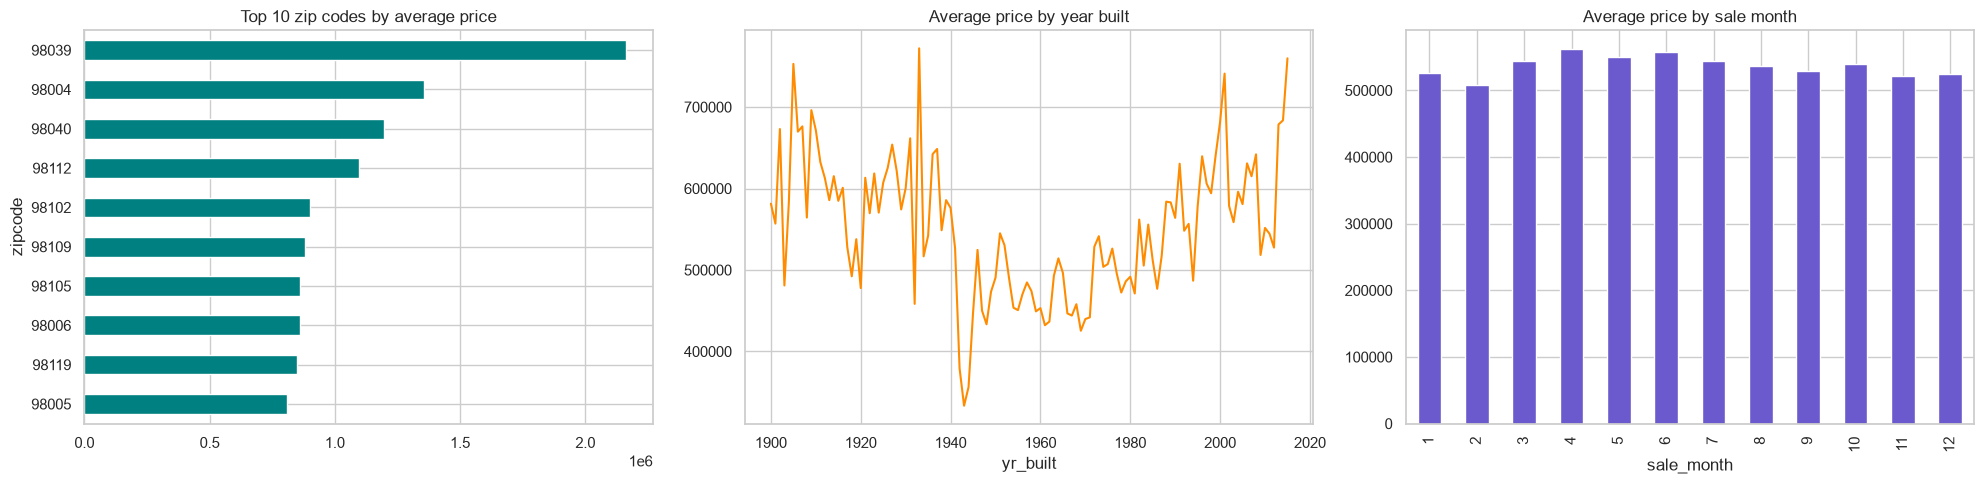

,average_price
zipcode,
98039,2.160607e+06
98004,1.355927e+06
98040,1.194230e+06
98112,1.095499e+06
98102,9.012583e+05
98109,8.796236e+05
98105,8.628252e+05
98006,8.596848e+05
98119,8.494480e+05


,average_price
sale_month,
1,525870.889571
2,507851.371200
3,543977.187200
4,561837.774989
5,550768.785833
6,558002.199541
7,544788.764360
8,536445.276804
9,529253.821871


In [15]:
top_zipcodes = data.groupby('zipcode')['price'].mean().nlargest(10).sort_values()
average_by_year = data.groupby('yr_built')['price'].mean()
average_by_month = (
    pd.to_datetime(data['date'], format='%Y%m%dT%H%M%S')
    .dt.month.to_frame('sale_month')
    .join(data['price'])
    .groupby('sale_month')['price'].mean()
)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
top_zipcodes.plot(kind='barh', color='teal', title='Top 10 zip codes by average price', ax=axes[0])
average_by_year.plot(color='darkorange', title='Average price by year built', ax=axes[1])
average_by_month.plot(kind='bar', color='slateblue', title='Average price by sale month', ax=axes[2])
plt.tight_layout()
plt.show()

display(top_zipcodes.sort_values(ascending=False).to_frame('average_price'))
display(average_by_month.to_frame('average_price'))

**Insight.** Location is strongly associated with average price. Year-built and sale-month patterns are descriptive, not proof of causal effects.

## 3. Clean identifiers, dates, duplicates, and impossible values

In [16]:
clean_data = data.drop(columns=['Unnamed: 0', 'id']).copy()
clean_data['date'] = pd.to_datetime(clean_data['date'], format='%Y%m%dT%H%M%S')

rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates().copy()
duplicates_removed = rows_before - len(clean_data)

invalid_bedrooms = clean_data['bedrooms'].gt(15)
invalid_bathrooms = clean_data['bathrooms'].le(0)
clean_data = clean_data.loc[~(invalid_bedrooms | invalid_bathrooms)].copy()

print(f'Duplicates removed: {duplicates_removed:,}')
print(f'Bedrooms above 15 removed: {invalid_bedrooms.sum():,}')
print(f'Zero or negative bathrooms removed: {invalid_bathrooms.sum():,}')
print(f'Clean data shape: {clean_data.shape}')

Duplicates removed: 0
Bedrooms above 15 removed: 1
Zero or negative bathrooms removed: 0
Clean data shape: (21612, 20)


**Cleaning decision.** The exported index and property identifier do not generalize. The value of 33 bedrooms is implausible and is removed. Any zero-bathroom values would also be removed.

## 3. Define missing-value and outlier handling

In [17]:
print(f'Missing bedrooms: {clean_data["bedrooms"].isna().sum():,}')
print(f'Missing bathrooms: {clean_data["bathrooms"].isna().sum():,}')
print(f'Bedroom median: {clean_data["bedrooms"].median():.1f}')
print(f'Bathroom median: {clean_data["bathrooms"].median():.2f}')
print('Median imputation happens inside the training pipeline to avoid leakage.')
print('Plausible IQR outliers are retained and handled with RobustScaler and log1p(price).')

Missing bedrooms: 13
Missing bathrooms: 10
Bedroom median: 3.0
Bathroom median: 2.25
Median imputation happens inside the training pipeline to avoid leakage.
Plausible IQR outliers are retained and handled with RobustScaler and log1p(price).


**Cleaning decision.** Median imputation retains nearly all rows and is robust to extreme homes. It is fit only on training data. Valid outliers stay in the data because they are part of the target market.

## 4. Engineer new features

In [18]:
model_data = clean_data.copy()
model_data['sale_year'] = model_data['date'].dt.year
model_data['sale_month'] = model_data['date'].dt.month
model_data['house_age'] = (model_data['sale_year'] - model_data['yr_built']).clip(lower=0)
model_data['is_renovated'] = (model_data['yr_renovated'] > 0).astype(int)
model_data['years_since_renovation'] = np.where(
    model_data['is_renovated'].eq(1),
    (model_data['sale_year'] - model_data['yr_renovated']).clip(lower=0),
    model_data['house_age']
)
model_data['total_rooms'] = model_data['bedrooms'] + model_data['bathrooms']
model_data['price_per_sqft'] = model_data['price'] / model_data['sqft_living'].clip(lower=1)
model_data['has_basement'] = (model_data['sqft_basement'] > 0).astype(int)
model_data['living_to_lot_ratio'] = model_data['sqft_living'] / model_data['sqft_lot'].clip(lower=1)

new_features = [
    'house_age', 'is_renovated', 'years_since_renovation', 'total_rooms',
    'price_per_sqft', 'has_basement', 'living_to_lot_ratio', 'sale_year', 'sale_month'
]
display(model_data[new_features].head())
print(f'Feature-engineered shape: {model_data.shape}')

,house_age,is_renovated,years_since_renovation,total_rooms,price_per_sqft,has_basement,living_to_lot_ratio,sale_year,sale_month
0,59,0,59,4.00,188.050847,0,0.208850,2014,10
1,63,1,23,5.25,209.338521,1,0.354874,2014,12
2,82,0,82,3.00,233.766234,0,0.077000,2015,2
3,49,0,49,7.00,308.163265,1,0.392000,2014,12
4,28,0,28,5.00,303.571429,0,0.207921,2015,2


Feature-engineered shape: (21612, 29)


**Why these features help.** Age and renovation describe condition over time. Room count, basement presence, and the living-to-lot ratio add interpretable space signals. Sale year and month retain timing. Price per square foot is analysis-only because it contains the target.

## 5. Choose model features and encoding approach

In [19]:
target = model_data['price'].copy()
drop_for_model = [
    'price', 'date', 'price_per_sqft', 'sqft_above', 'sqft_basement',
    'yr_built', 'yr_renovated'
]
features = model_data.drop(columns=drop_for_model).copy()
features['zipcode'] = features['zipcode'].astype(str)

categorical_features = ['zipcode']
numeric_features = [column for column in features.columns if column not in categorical_features]

print(f'Feature matrix shape: {features.shape}')
print(f'Numeric features: {numeric_features}')
print(f'Categorical features: {categorical_features}')

Feature matrix shape: (21612, 22)
Numeric features: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'is_renovated', 'years_since_renovation', 'total_rooms', 'has_basement', 'living_to_lot_ratio']
Categorical features: ['zipcode']


**Encoding decision.** Zip code is one-hot encoded because it labels locations rather than representing an ordered quantity. Price per square foot is excluded to avoid target leakage.

## 6. Check multicollinearity with VIF

In [20]:
def calculate_vif(frame):
    values = frame.copy().fillna(frame.median(numeric_only=True))
    values = (values - values.mean()) / values.std(ddof=0)
    correlation = np.corrcoef(values.to_numpy(), rowvar=False)
    inverse_correlation = np.linalg.pinv(correlation)
    return pd.DataFrame({
        'feature': frame.columns,
        'vif': np.diag(inverse_correlation)
    }).sort_values('vif', ascending=False)

vif_features = [
    'sqft_living', 'sqft_above', 'sqft_basement', 'sqft_lot',
    'bedrooms', 'bathrooms', 'grade', 'house_age'
]
display(calculate_vif(model_data[vif_features]))

living_area_identity = model_data['sqft_living'].eq(
    model_data['sqft_above'] + model_data['sqft_basement']
).mean()
print(f'Living area identity holds for {living_area_identity:.1%} of rows.')

,feature,vif
5,bathrooms,3.018422
6,grade,2.916475
4,bedrooms,1.663794
7,house_age,1.590239
1,sqft_above,1.170312
0,sqft_living,1.097742
3,sqft_lot,1.049202
2,sqft_basement,1.004352


Living area identity holds for 100.0% of rows.


**Feature-selection decision.** Total living area equals above-ground area plus basement area, so keeping all three causes structural multicollinearity. The model keeps total living area and a basement flag, while dropping the two redundant components. House age and renovation features replace raw year fields.

## 7. Create leakage-safe preprocessing

In [21]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)
])

print('RobustScaler is used because numeric size features contain IQR outliers.')
print('The preprocessor is inside every model pipeline and is fit on training data only.')

RobustScaler is used because numeric size features contain IQR outliers.
The preprocessor is inside every model pipeline and is fit on training data only.


## 8. Create the 80/20 train and test split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=RANDOM_STATE
)
print(f'Training rows: {len(X_train):,}')
print(f'Test rows: {len(X_test):,}')

Training rows: 17,289
Test rows: 4,323


## 9. Define reusable modeling and evaluation functions

In [23]:
def build_model(regressor):
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', regressor)
    ])
    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )


def evaluate_predictions(y_true, y_pred, train_r2, feature_count):
    test_r2 = r2_score(y_true, y_pred)
    sample_count = len(y_true)
    adjusted_r2 = 1 - (1 - test_r2) * (sample_count - 1) / (sample_count - feature_count - 1)
    return {
        'train_r2': train_r2,
        'test_r2': test_r2,
        'adjusted_r2': adjusted_r2,
        'mae': mean_absolute_error(y_true, y_pred),
        'mse': mean_squared_error(y_true, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_true, y_pred))
    }

## 9. Define baseline models

In [24]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10.0),
    'Lasso': Lasso(alpha=0.0005, max_iter=10000),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=60, max_features=0.8, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=80, learning_rate=0.05, max_depth=3,
        min_samples_leaf=10, random_state=RANDOM_STATE
    )
}

try:
    from xgboost import XGBRegressor
    models['XGBoost'] = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        objective='reg:squarederror', random_state=RANDOM_STATE, n_jobs=-1
    )
    print('XGBoost is available and will be evaluated.')
except ImportError:
    print('XGBoost is not installed. Install xgboost to run its comparison.')

print(list(models))

XGBoost is available and will be evaluated.
['Linear Regression', 'Ridge', 'Lasso', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']


## 9. Fit baseline models and compare holdout metrics

In [25]:
baseline_rows = []
fitted_models = {}
feature_count = None

for name, estimator in models.items():
    fitted_model = build_model(estimator)
    fitted_model.fit(X_train, y_train)

    if feature_count is None:
        feature_count = len(
            fitted_model.regressor_.named_steps['preprocessor'].get_feature_names_out()
        )

    predictions = fitted_model.predict(X_test)
    metrics = evaluate_predictions(
        y_test,
        predictions,
        fitted_model.score(X_train, y_train),
        feature_count
    )
    metrics['model'] = name
    baseline_rows.append(metrics)
    fitted_models[name] = fitted_model

baseline_table = pd.DataFrame(baseline_rows).sort_values('test_r2', ascending=False)
display(baseline_table.round(4))

,train_r2,test_r2,adjusted_r2,mae,mse,rmse,model
6,0.9229,0.8954,0.8932,67909.8776,1.569533e+10,125280.9907,XGBoost
4,0.9692,0.8740,0.8713,72226.2968,1.890351e+10,137490.0410,Random Forest
3,0.8805,0.7991,0.7948,91269.3501,3.015249e+10,173644.7190,Decision Tree
5,0.7954,0.7959,0.7915,89852.2452,3.062964e+10,175013.2595,Gradient Boosting
1,0.8292,0.6595,0.6522,80928.7575,5.110298e+10,226059.6841,Ridge
0,0.8191,0.6491,0.6415,80914.3388,5.266818e+10,229495.4976,Linear Regression
2,0.8350,0.6461,0.6385,83732.4943,5.311294e+10,230462.4557,Lasso


**Interpretation.** Compare train and test R2 to detect overfitting. MAE, MSE, and RMSE are calculated on the original price scale.

## 9. Run five-fold cross-validation

In [26]:
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, estimator in models.items():
    scores = cross_validate(
        build_model(estimator),
        features,
        target,
        cv=folds,
        scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'},
        n_jobs=1
    )
    cv_rows.append({
        'model': name,
        'cv_r2_mean': scores['test_r2'].mean(),
        'cv_r2_std': scores['test_r2'].std(),
        'cv_mae_mean': -scores['test_mae'].mean()
    })

cv_table = pd.DataFrame(cv_rows).sort_values('cv_r2_mean', ascending=False)
display(cv_table.round(4))

,model,cv_r2_mean,cv_r2_std,cv_mae_mean
6,XGBoost,0.8885,0.0119,65735.6261
4,Random Forest,0.8691,0.0091,69200.1019
1,Ridge,0.7970,0.0733,76738.1584
2,Lasso,0.7967,0.0770,79462.9239
3,Decision Tree,0.7942,0.0074,87892.8250
0,Linear Regression,0.7891,0.0758,76168.3676
5,Gradient Boosting,0.7872,0.0230,86868.1257


**Interpretation.** A high average cross-validation R2 with a small standard deviation is more stable than a favorable score from one split alone.

## 9. Tune Random Forest and Gradient Boosting

In [27]:
tuning_spaces = {
    'Random Forest (tuned)': (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {
            'regressor__model__n_estimators': [30, 45, 60],
            'regressor__model__max_depth': [None, 18],
            'regressor__model__min_samples_leaf': [1, 2, 4],
            'regressor__model__max_features': [0.7, 0.9]
        }
    ),
    'Gradient Boosting (tuned)': (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            'regressor__model__n_estimators': [80, 120],
            'regressor__model__learning_rate': [0.03, 0.05, 0.08],
            'regressor__model__max_depth': [2, 3],
            'regressor__model__min_samples_leaf': [5, 10]
        }
    )
}

tuned_rows = []
tuned_models = {}
for name, (estimator, parameters) in tuning_spaces.items():
    search = RandomizedSearchCV(
        estimator=build_model(estimator),
        param_distributions=parameters,
        n_iter=3,
        scoring='r2',
        cv=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    metrics = evaluate_predictions(
        y_test,
        search.predict(X_test),
        search.score(X_train, y_train),
        feature_count
    )
    metrics['model'] = name
    metrics['best_cv_r2'] = search.best_score_
    metrics['best_parameters'] = str(search.best_params_)
    tuned_rows.append(metrics)
    tuned_models[name] = search.best_estimator_

tuned_table = pd.DataFrame(tuned_rows).sort_values('test_r2', ascending=False)
display(tuned_table.round(4))

,train_r2,test_r2,adjusted_r2,mae,mse,rmse,model,best_cv_r2,best_parameters
0,0.9684,0.8647,0.8618,72920.1352,2.030827e+10,142507.0799,Random Forest (tuned),0.8585,"{'regressor__model__n_estimators': 45, 'regres..."
1,0.7874,0.7915,0.7870,91288.1106,3.129156e+10,176894.2140,Gradient Boosting (tuned),0.7733,"{'regressor__model__n_estimators': 80, 'regres..."


**Tuning decision.** The two tree ensembles are tuned because they can model non-linear relationships and interactions among property size, quality, and location.

## 10. Choose the best model and print final metrics

In [28]:
final_table = pd.concat([
    baseline_table,
    tuned_table.drop(columns=['best_parameters'], errors='ignore')
], ignore_index=True).sort_values('test_r2', ascending=False).reset_index(drop=True)
display(final_table.round(4))

best_model_name = final_table.loc[0, 'model']
best_model = {**fitted_models, **tuned_models}[best_model_name]
best_predictions = best_model.predict(X_test)

print(f'Best model: {best_model_name}')
print(f'Test R2: {r2_score(y_test, best_predictions):.4f}')
print(f'Test Adjusted R2: {final_table.loc[0, "adjusted_r2"]:.4f}')
print(f'Test MAE: USD {mean_absolute_error(y_test, best_predictions):,.0f}')
print(f'Test MSE: {mean_squared_error(y_test, best_predictions):,.0f}')
print(f'Test RMSE: USD {np.sqrt(mean_squared_error(y_test, best_predictions)):,.0f}')

,train_r2,test_r2,adjusted_r2,mae,mse,rmse,model,best_cv_r2
0,0.9229,0.8954,0.8932,67909.8776,1.569533e+10,125280.9907,XGBoost,NaN
1,0.9692,0.8740,0.8713,72226.2968,1.890351e+10,137490.0410,Random Forest,NaN
2,0.9684,0.8647,0.8618,72920.1352,2.030827e+10,142507.0799,Random Forest (tuned),0.8585
3,0.8805,0.7991,0.7948,91269.3501,3.015249e+10,173644.7190,Decision Tree,NaN
4,0.7954,0.7959,0.7915,89852.2452,3.062964e+10,175013.2595,Gradient Boosting,NaN
5,0.7874,0.7915,0.7870,91288.1106,3.129156e+10,176894.2140,Gradient Boosting (tuned),0.7733
6,0.8292,0.6595,0.6522,80928.7575,5.110298e+10,226059.6841,Ridge,NaN
7,0.8191,0.6491,0.6415,80914.3388,5.266818e+10,229495.4976,Linear Regression,NaN
8,0.8350,0.6461,0.6385,83732.4943,5.311294e+10,230462.4557,Lasso,NaN


Best model: XGBoost
Test R2: 0.8954
Test Adjusted R2: 0.8932
Test MAE: USD 67,910
Test MSE: 15,695,326,629
Test RMSE: USD 125,281


## 10. Plot actual versus predicted values and residuals

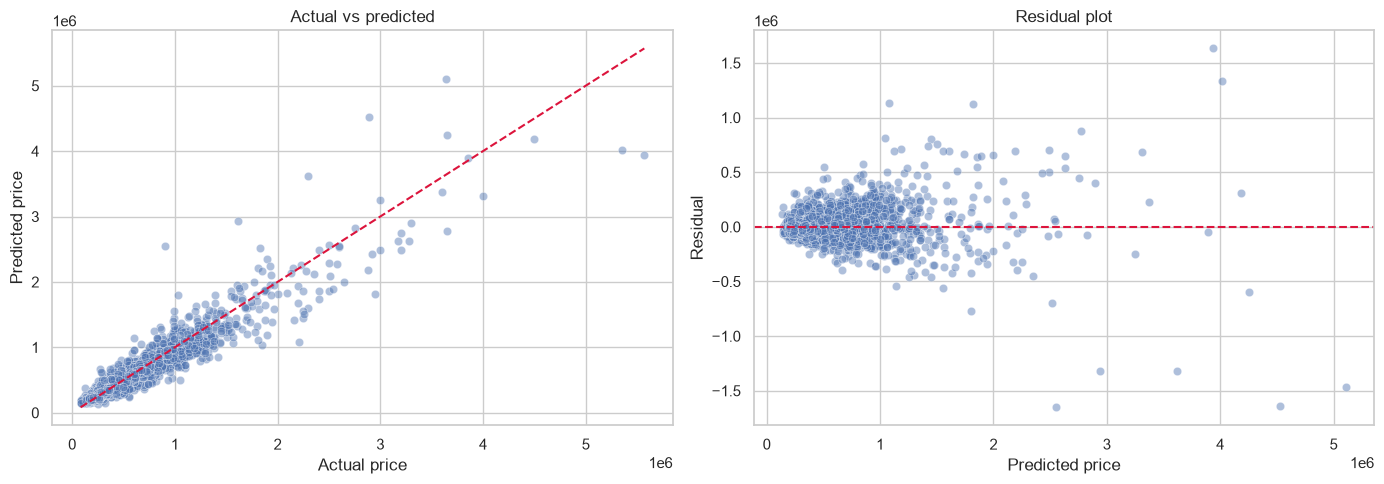

count    4.323000e+03
mean     9.500966e+03
std      1.249347e+05
min     -1.651972e+06
25%     -3.603583e+04
50%      1.728500e+03
75%      4.339134e+04
max      1.632904e+06
Name: price, dtype: float64


In [29]:
residuals = y_test - best_predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_test, y=best_predictions, alpha=0.45, ax=axes[0])
limits = [min(y_test.min(), best_predictions.min()), max(y_test.max(), best_predictions.max())]
axes[0].plot(limits, limits, '--', color='crimson')
axes[0].set_xlabel('Actual price')
axes[0].set_ylabel('Predicted price')
axes[0].set_title('Actual vs predicted')

sns.scatterplot(x=best_predictions, y=residuals, alpha=0.45, ax=axes[1])
axes[1].axhline(0, linestyle='--', color='crimson')
axes[1].set_xlabel('Predicted price')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual plot')
plt.tight_layout()
plt.show()

print(residuals.describe())

**Insight.** Points close to the diagonal represent accurate predictions. Residuals should be centered around zero; wider spread at high prices is common for rare luxury homes.

## 10. Plot feature importance for the best model

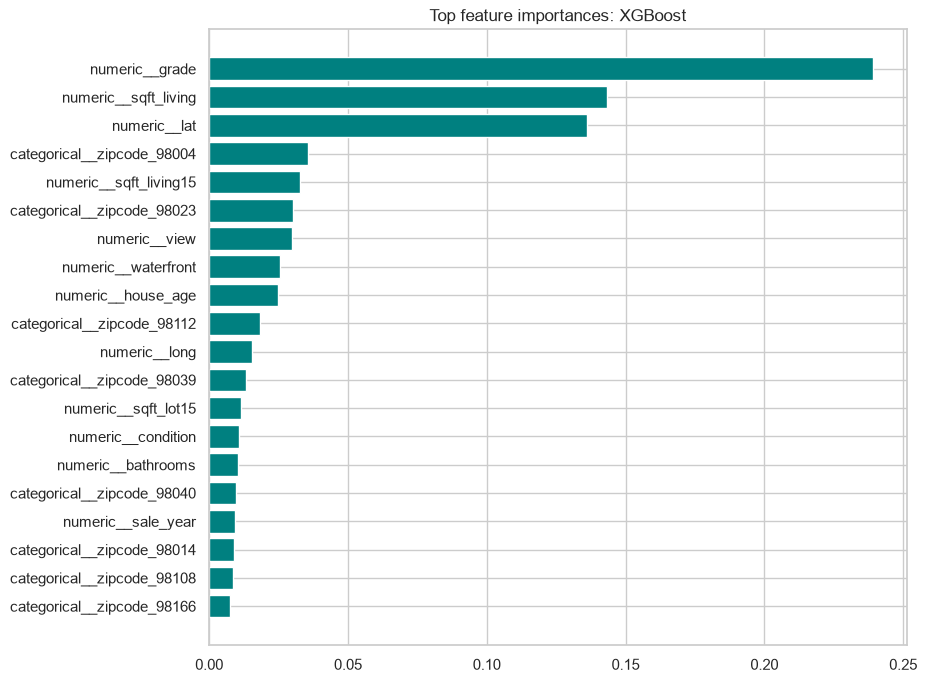

,feature,importance
8,numeric__grade,0.239299
2,numeric__sqft_living,0.143288
9,numeric__lat,0.135957
24,categorical__zipcode_98004,0.035493
11,numeric__sqft_living15,0.032763
34,categorical__zipcode_98023,0.030178
6,numeric__view,0.029818
5,numeric__waterfront,0.025604
15,numeric__house_age,0.024694
69,categorical__zipcode_98112,0.018181


In [30]:
final_pipeline = best_model.regressor_
final_estimator = final_pipeline.named_steps['model']
feature_names = final_pipeline.named_steps['preprocessor'].get_feature_names_out()

if hasattr(final_estimator, 'feature_importances_'):
    importance_values = final_estimator.feature_importances_
else:
    importance_values = np.abs(np.ravel(final_estimator.coef_))

importance_table = pd.DataFrame({
    'feature': feature_names,
    'importance': importance_values
}).nlargest(20, 'importance').sort_values('importance')

plt.figure(figsize=(9, 8))
plt.barh(importance_table['feature'], importance_table['importance'], color='teal')
plt.title(f'Top feature importances: {best_model_name}')
plt.show()
display(importance_table.sort_values('importance', ascending=False))

**Insight.** The feature-importance ranking is a model-based check on the EDA. Important area, grade, and location inputs support the earlier findings.

## 11. Final report template

### Objective and dataset
Predict King County house sale price from property, location, and sale-date information. Dataset size: [FILL AFTER RUN].

### Cleaning decisions
Dropped the exported index and identifier, converted date to datetime, removed impossible bedroom and bathroom values, retained plausible IQR outliers, and median-imputed missing bedrooms and bathrooms inside the training pipeline. Fill final row counts and medians: [FILL AFTER RUN].

### Key EDA insights
Raw price skewness: [FILL AFTER RUN]. Log-price skewness: [FILL AFTER RUN]. Strongest price relationships, top zip codes, and geographic patterns: [FILL AFTER RUN].

### New features
The workflow creates house age, renovation status and recency, total rooms, basement flag, living-to-lot ratio, sale year, and sale month. Price per square foot is analysis-only because it would leak the target.

### Encoding, scaling, and feature selection
Zip code is one-hot encoded. Numeric features are median-imputed and robust-scaled inside the pipeline. Redundant area components are dropped after correlation and VIF checks.

### Models and final selection
Complete the model comparison table with test and five-fold cross-validation scores. Selected model: [FILL AFTER RUN]. Test R2: [FILL AFTER RUN]. Adjusted R2: [FILL AFTER RUN]. MAE: [FILL AFTER RUN]. MSE: [FILL AFTER RUN]. RMSE: [FILL AFTER RUN].

### Limitations and next steps
The data covers historical sales over roughly one year and omits some neighborhood, interior-condition, and market-timing factors. Next steps are time-based validation, approved external neighborhood data, retraining with new sales, and an XGBoost comparison when available.

The complete version of this template is also saved in report.md.